<a href="https://colab.research.google.com/github/Garyo14/Garyo14.github.io/blob/main/predictive_maintenance_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Maintenance for Heavy Equipment (Mining Context)

**Goal:** Predict machine/equipment failure using sensor data, adapted to a heavy-equipment maintenance context relevant to mining contractors (e.g. KPP Mining).

**Dataset:** [Machine Predictive Maintenance Classification](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification) (Kaggle)

**Author:** Tegar Haryo Wibowo

---

### How to use this notebook
1. Download `predictive_maintenance.csv` from the Kaggle link above.
2. Place it in the same folder as this notebook (or update the `DATA_PATH` variable below).
3. Run cells top to bottom.

### Plan
- **Day 1:** Data loading, cleaning, EDA
- **Day 2:** Preprocessing, modeling (Logistic Regression + Random Forest), evaluation
- **Day 3:** Feature importance, business insight, narrative for portfolio

## Day 1 — Setup & Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
#karena aku mau up di google drive, makanya pake sintaks itu"
from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = "/content/drive/My Drive/Project_Maintenance/predictive_maintenance.csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head()
df.tail()

Mounted at /content/drive
Shape: (10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,No Failure


# Pre-processing

In [ ]:
# Basic structure check
df.info()
print("\nMissing values per column:") # cek berapa banyak kolom yang ada missing values
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotatio

dari hasil diatas, dapat diketahui, bahwa:
1. terdapat 10000 data, ada 10 kolom
2. terdiri dari 3 float artinya angka desimal (suhu/temperatur, kecepatan putar), 4 int yaitu angka bulat (urutan aja: ada 1->9999, kecepatan putar, Keausan alat, target), dan 3 objek/teks (produk id, tipe, tipe kegagalan)
3. tidak ada duplikat
4. tidak ada missing values

Di dataset ini, kolom Type dibagi menjadi tiga kategori: H (High/Tinggi), M (Medium/Sedang), dan L (Low/Rendah). Ini menunjukkan tingkat kualitas atau grade dari komponen/beban kerja yang sedang diproduksi atau dikerjakan oleh mesin.

Pengaruh ke Keausan (Tool wear): akumulasi berapa lama alat tersebut telah digunakan dalam proses produksi.

### Rename columns for a mining/heavy-equipment framing (optional but recommended for storytelling)
The original dataset uses generic industrial-machine column names. Renaming them (in a copy) makes
the narrative read naturally as a heavy-equipment maintenance case without altering the underlying data.

In [ ]:
# Adjust this mapping to match the actual column names in your downloaded CSV
rename_map = {
    "Air temperature [K]": "ambient_temp_k",
    "Process temperature [K]": "engine_temp_k",
    "Rotational speed [rpm]": "rotational_speed_rpm",
    "Torque [Nm]": "torque_nm",
    "Tool wear [min]": "component_wear_min",
    "Target": "failure",
    "Failure Type": "failure_type",
    "Type": "equipment_type",
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})
df.head()

,UDI,Product ID,equipment_type,ambient_temp_k,engine_temp_k,rotational_speed_rpm,torque_nm,component_wear_min,failure,failure_type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


In [ ]:
# Basic structure check
df.info()
print("\nMissing values per column:") # cek berapa banyak kolom yang ada missing values
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   UDI                   10000 non-null  int64  
 1   Product ID            10000 non-null  object 
 2   equipment_type        10000 non-null  object 
 3   ambient_temp_k        10000 non-null  float64
 4   engine_temp_k         10000 non-null  float64
 5   rotational_speed_rpm  10000 non-null  int64  
 6   torque_nm             10000 non-null  float64
 7   component_wear_min    10000 non-null  int64  
 8   failure               10000 non-null  int64  
 9   failure_type          10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB

Missing values per column:
UDI                     0
Product ID              0
equipment_type          0
ambient_temp_k          0
engine_temp_k           0
rotational_speed_rpm    0
torque_nm               0
compon

Setelah proses sebelumnya tidak ada error yang terjadi

## Day 1 — Exploratory Data Analysis (EDA)

failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64
failure
0    9661
1     339
Name: count, dtype: int64


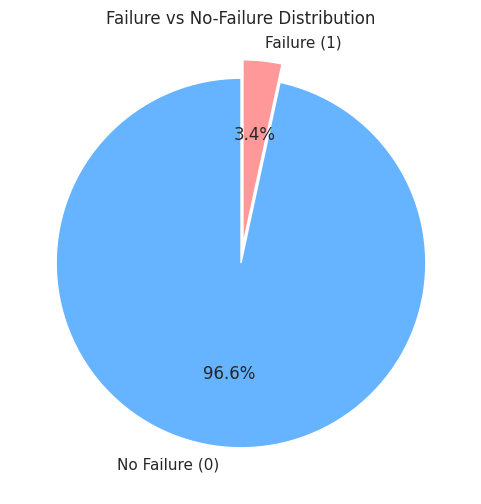

In [ ]:
# Target distribution — how imbalanced is failure vs no-failure?
target_col = "failure"  # update if your target column has a different name
print(df[target_col].value_counts(normalize=True))
print(df[target_col].value_counts())
# Membuat pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    df[target_col].value_counts(normalize=True),
    labels=['No Failure (0)', 'Failure (1)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#66b3ff', '#ff9999'],
    explode=(0, 0.1),
)  # Sedikit 'menonjolkan' bagian failure agar lebih terlihat
plt.title("Failure vs No-Failure Distribution")
plt.show()

Jelas bahwa No failure samgat mendominasi, kita cek mana saja yang failure untuk cek contohnya

In [ ]:
df_failure = df[df["failure"]==1]
df_failure.tail()

,UDI,Product ID,equipment_type,ambient_temp_k,engine_temp_k,rotational_speed_rpm,torque_nm,component_wear_min,failure,failure_type
9758,9759,L56938,L,298.6,309.8,2271,16.2,218,1,Tool Wear Failure
9764,9765,L56944,L,298.5,309.5,1294,66.7,12,1,Power Failure
9822,9823,L57002,L,298.5,309.4,1360,60.9,187,1,Overstrain Failure
9830,9831,L57010,L,298.3,309.3,1337,56.1,206,1,Overstrain Failure
9974,9975,L57154,L,298.6,308.2,1361,68.2,172,1,Power Failure


setelah diketahui bahwa data imbalance maka selanjutnya akan dicek skewnessnya berdasarkan visualisasi atau dengan kata lain akan dicek penyebaran datanya apakah terlalu miring ke kanan atau kekiri yang nanti kalo memang terlalu ekstrim skewnessnya akan ditransformasi menggunakan log dll sebelum melakukan LR, karena LR itu sensitif pada distribusi ini

mean:
ambient_temp_k           300.00493
engine_temp_k            310.00556
rotational_speed_rpm    1538.77610
torque_nm                 39.98691
component_wear_min       107.95100
dtype: float64
 
std:
ambient_temp_k            2.000259
engine_temp_k             1.483734
rotational_speed_rpm    179.284096
torque_nm                 9.968934
component_wear_min       63.654147
dtype: float64
 
skew:
ambient_temp_k          0.114274
engine_temp_k           0.015027
rotational_speed_rpm    1.993171
torque_nm              -0.009517
component_wear_min      0.027292
dtype: float64
 
kurtosis:
ambient_temp_k         -0.835962
engine_temp_k          -0.499734
rotational_speed_rpm    7.392945
torque_nm              -0.013241
component_wear_min     -1.166737
dtype: float64


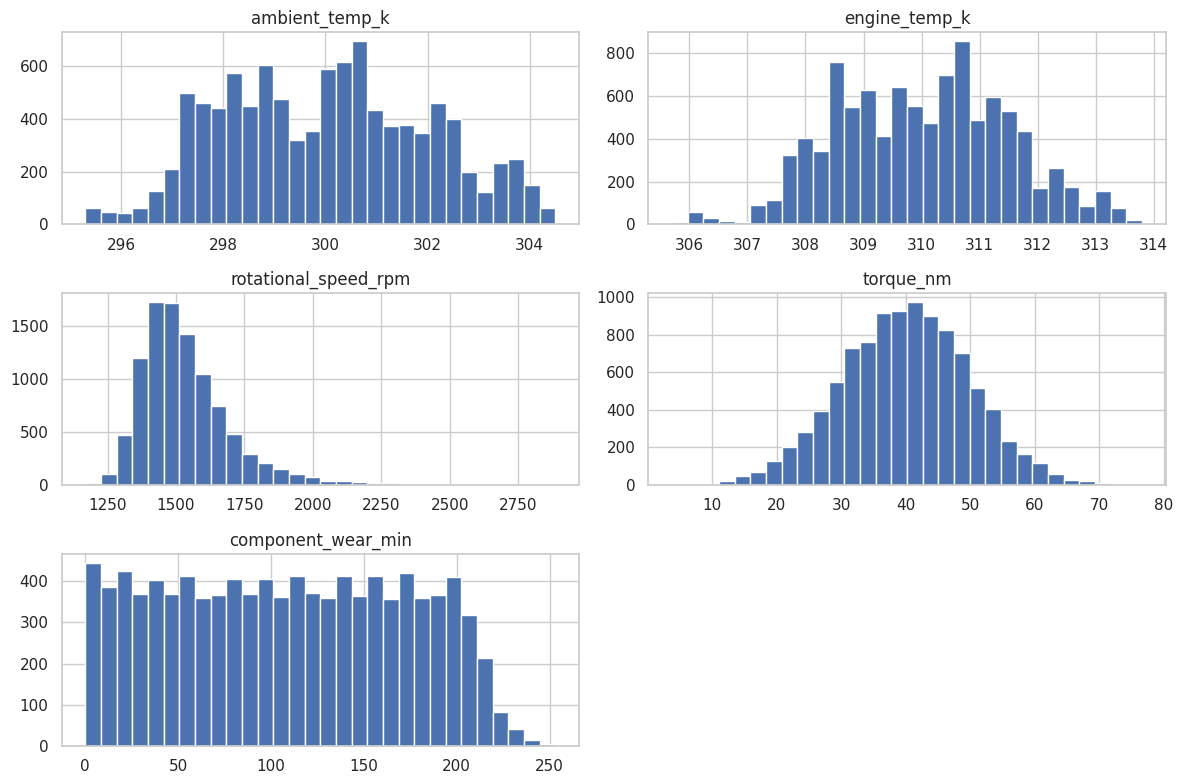

In [ ]:
#Penyebaran data menggunakan histogram
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in [target_col, 'UDI']]  # ini dilakukan untuk hati hati karena target_col sebelumnya juga numerik
print("mean:")
print(df[numeric_cols].mean())
print(" ")
print("std:")
print(df[numeric_cols].std())
print(" ")
print("skew:")
print(df[numeric_cols].skew())
print(" ")
print("kurtosis:")
print(df[numeric_cols].kurtosis())

df[numeric_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

saat ini, grafik yang ditunjukkan sulit untuk direpresentastikan, terutama untuk kolom component_wear_min maka dari itu akan dicari nilainya saja.

Berdasarkan nilai yang diperoleh:
Rotational_speed_rpm menunjukkan skewness tinggi sebesar 1.99 dan kurtosis tinggi 7.39, mengidentifikasikan distribusi menceng ke kanan dengan outlier ekstrem. Kolom lain seperti ambient_temp_k, engine_temp_k, torque_nm, component_wear_min menunjukkan skewness mendekati 0 sehingga relatif simetris dan tifak memerlukan transformasi.

Dengan demikian, disarankan untuk melakukan transformassi (seperti log-transform atau copping outlier) untuk kolom Rotational_speed_rpm sebelum digunakan pada model regresi logistik, untuk menstabilkan proses optimisasi dan efektivitas scalling

#List comprehension
numeric_cols = [c for c in numerical_cols if c not in [target_col]]

inget kolom di df yang numerik juga ada yang target col 0 dan 1

kalo dalam bentuk looping biasa
hasil = []
for c in numeric_cols
	if c not in [target_col]
		hasil.append(c)   kalua bukan, masukkan ke list baru
numeric_cols = hasil

disini, kita ga melakukan jumlah interval dll jadi itu diwakili oleh bins = 30 yang artinya minta pandas untuk membagi data data di kolom itu jadi 30 bagian sama besar

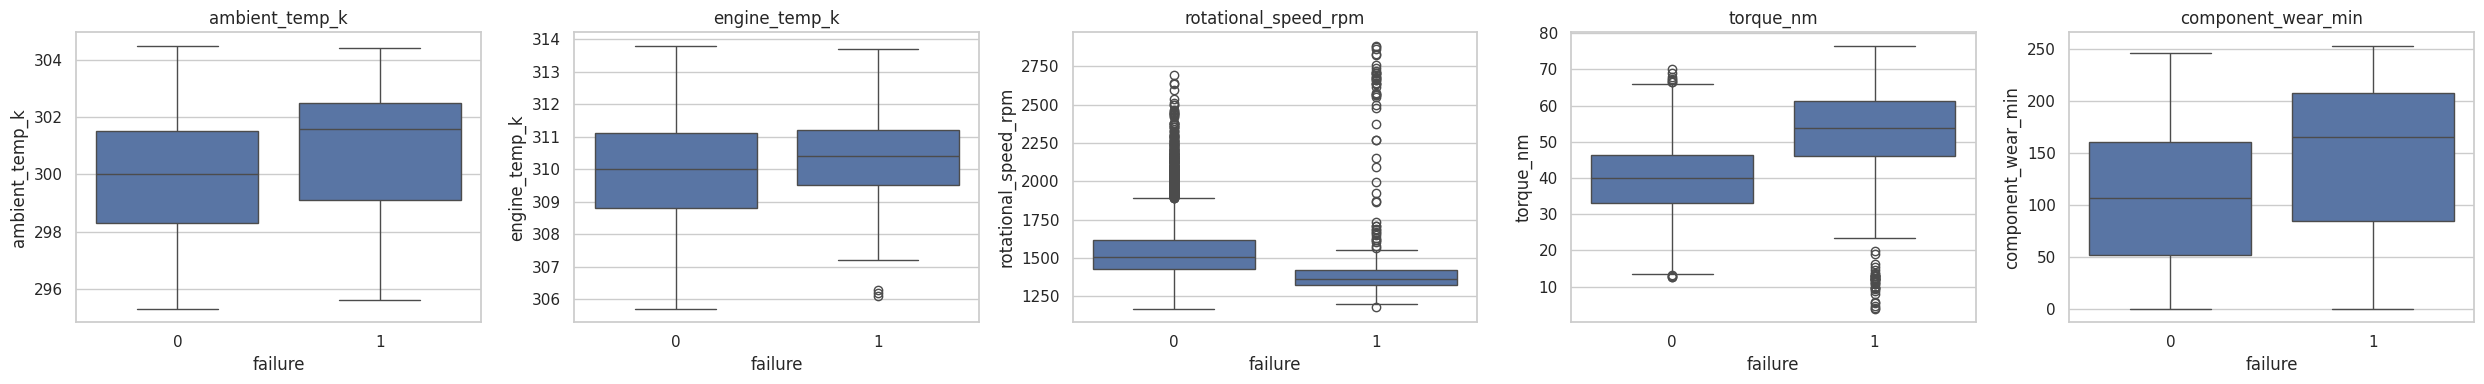

In [ ]:
# Feature vs failure boxplots — which sensor readings differ most between failure/no-failure?
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(5 * len(numeric_cols), 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x=target_col, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

terlhat jelas bahwa untuk kolom rotational_speed_rpm memiliki outlier yang banyak sedangkan untuk kolom torque_nm dan engine_temp_k terdapat outlier namun tidak sebanyak rotational_speed_rpm, apalagi engine_temp_k hanya 1 outlier

Boxplot adalah penyajian grafis berbentuk box (kotak) dan whisker (kumis).

Bagian Utama dari boxplot adalah kotak yang merupakan bidang untuk menampilkan IQR (Inner Quartile Range).
Dalam bagian kotak terdapat 50% nilai data pengamatan.
Panjang kotak = jangkauan kuartil dalam yaitu selisih (Q3) dengan Q1.

1. Semakin Panjang kotaknya maka semakin menyebar datanya atau dengan kata lain datanya berisik (noisy) dan kurang bisa diandalkan sebagai pembeda.
paling kecil yaitu rotational_speen_rpm, torque_nm, dan engine_temp_k

2. Dapat dilihat dari posisi median, seberapa jauh posisi median bergeser dari kedua keputusan tersebut, dimana semakin jauh bergeser, semakin kuat kolom itu sebagai pembeda, jika dilihat dari grafik boxplot yang dihasilkan:
a. torque_nm, component_wear_min, rotational_speed_rpm, dan ambient_temp_k memiliki indikasi kuat sebagai pembeda

3. Seberapa besar overlap antar dua kotak, bayangkan saja mereka saling tumpeng tinfinh, dimana liat mana kolom yang jkda tumpeng tindih saling pisah dan menyatu atau banyak "irisannya"
a. ambient_temp_k overlap besar
b engine_temp_k overlap cukup besar
c. rotational_speed_rpm overlap kecil
d. torque_nm overlap kecil
e. component_wear_min overlap sedang

semakin kecil atau tidak ada overlap, kolom tersebut dominan
2. Outlier pada national
Observasi boxplot bukan hanya melihat jumlah atau tidak/adanya outlier tapi lebih dari itu, tapi juga digunakan untuk melihat fitur mana yang paling prediktif atau berpengaruh terhadap prediksi

Fitur dengan indikasi kuat sebagai pembeda: torque_nm (overlap kecil, median beda jauh) dan component_wear_min (median bergeser, overlap sedang).
Fitur dengan sinyal sedang: rotational_speed_rpm, plus pola outlier ekstrem


In [ ]:
outlier_cols = ["rotational_speed_rpm"]
outlier_cols = [c for c in outlier_cols if c in outlier_cols]
print(df[outlier_cols].value_counts())

rotational_speed_rpm
1452                    48
1435                    43
1447                    42
1479                    40
1469                    40
                        ..
2478                     1
2372                     1
2497                     1
2514                     1
2540                     1
Name: count, Length: 941, dtype: int64


**Day 1 checkpoint — write your observations here:**
- Which features look most different between failure and no-failure cases?
Ada di kecepatan berputar mesin sama torque atau tenaga putar, karena dua
- How imbalanced is the target? (this affects which metric matters most in Day 2)
- Any surprising patterns worth mentioning in the final write-up?

---
## Day 2 — Preprocessing & Modeling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)

feature_cols = numeric_cols.copy()  # add encoded categorical columns here if relevant (e.g. equipment_type)

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (8000, 5) | Test shape: (2000, 5)


In [ ]:
# Model 1 — Logistic Regression (baseline, interpretable)
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Results")
print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_lr))

Logistic Regression Results
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.84      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.83      0.57      2000
weighted avg       0.96      0.82      0.88      2000

ROC-AUC: 0.907974059188893


In [ ]:
# Model 2 — Random Forest (usually stronger for tabular sensor data)
rf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("Random Forest Results")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

Random Forest Results
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.89      0.60      0.72        68

    accuracy                           0.98      2000
   macro avg       0.94      0.80      0.86      2000
weighted avg       0.98      0.98      0.98      2000

ROC-AUC: 0.9614503410059676


Terlihat bahwa Random forest lebih akurat atau lebih tinggi ketimbang logistic regression

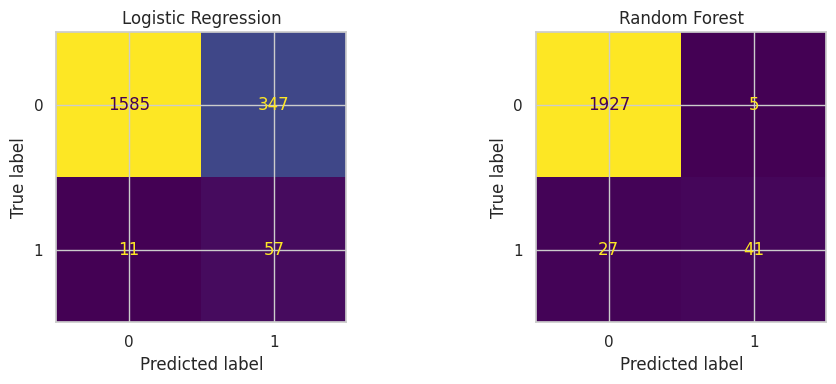

In [ ]:
# Confusion matrices side-by-side — for a maintenance use case, RECALL on the failure class matters most
# (missing an actual failure is far more costly than a false alarm)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_lr)).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Logistic Regression")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf)).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Random Forest")
plt.tight_layout()
plt.show()

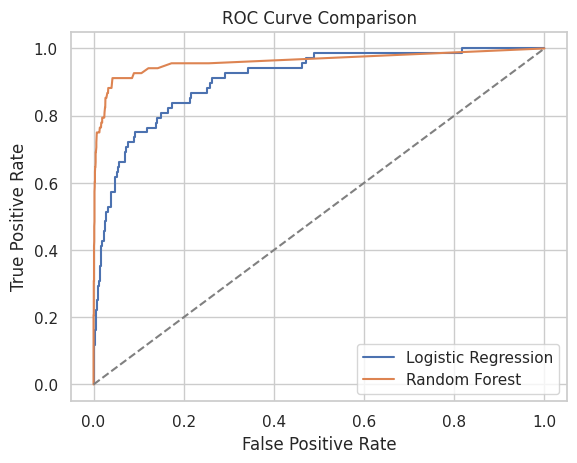

In [ ]:
# ROC curve comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

plt.plot(fpr_lr, tpr_lr, label="Logistic Regression")
plt.plot(fpr_rf, tpr_rf, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

**Day 2 checkpoint — write your observations here:**
- Which model performs better, and on which metric specifically?
Model randon forest memberikan performa yang terbaik. Trade-off ini punya implikasi biaya nyata: Logistic Regression, meminimalkan kegagalan yang terlewat (11 kasus) namun menghasilkan banyak false alarm (347 kasus) yang bisa membebani tim maintenance secara operaiona;. Sebaliknya, Random Forest jauh lebih efisien dalam mengurangi false alram (5 kasus)< namun berisiko melewatkan lebih banyak kegagalan aktual (27 kaasus). Pemilihan model akhirnya bergantung pada mana yang lebih mahal bagi bisnis: biaya insperksi berlebih atau biaya downtime akibat kegagalan tak berdeteksi
- Given a maintenance context, is recall or precision more important — and does your chosen model reflect that?
Dalam konteks maintenance, recall lebih penting karena biaya melewatkan kegagalan aktual (downtime tak terduga, kerusakan lebih parah, bahkan risiko keselamatan) jauh lebih mahal dibanding biaya inspeksi tambahan akibat false alaram. Oleh karena itu, dipilih Logistic Regression karena recall-nya lebih tinggi (0.84 vs 0.60), meski precission-nya lebih rendah.

---
## Day 3 — Feature Importance & Business Insight

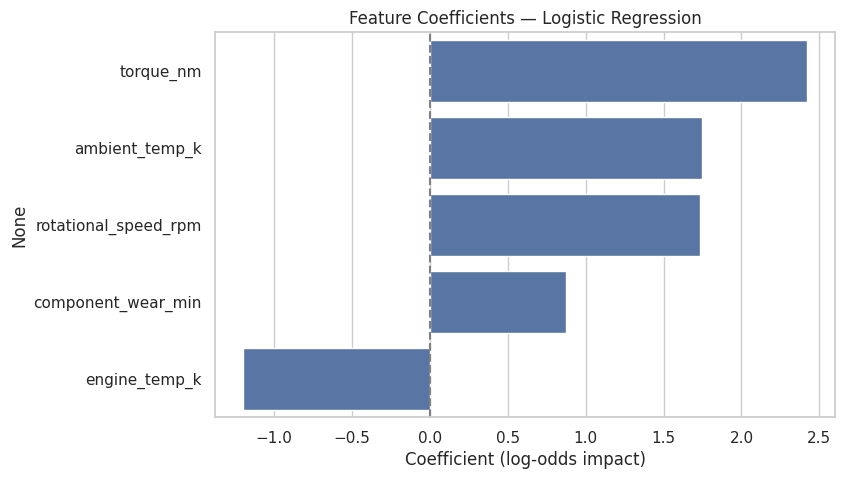

torque_nm               2.420522
ambient_temp_k          1.748740
rotational_speed_rpm    1.735670
component_wear_min      0.872298
engine_temp_k          -1.198877
dtype: float64


In [ ]:
# Feature importance from Random Forest — this is the core of your business recommendation
lr_importances = pd.Series(log_reg.coef_[0], index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=lr_importances.values, y=lr_importances.index)
plt.title("Feature Coefficients — Logistic Regression")
plt.xlabel("Coefficient (log-odds impact)")
plt.axvline(x=0, color = 'gray', linestyle='--')
plt.show()

print(lr_importances)

**Hasil**
Makin tinggi torque, suhu, rotational speed, component wear maka semakin besar risiko falure
sedangkan temperatur mesin sebaliknya, semakin tinggi suhunya maka semakin kecil risio failure

### Business Insight Template (fill in after reviewing the feature importance chart)

> Based on the model, **torque** is the strongest predictor of equipment failure risk,
> followed by **rotational speed**. This suggests that a mining contractor's maintenance team should
> prioritise real-time monitoring of **torque and rotational speed**
> to schedule preventive maintenance before failure occurs, rather than relying purely on fixed-interval
> servicing schedules.
>
> With a recall of **84%** on the failure class (Logistic Regression), the model can flag the majority of at-risk equipment in
> advance, reducing unplanned downtime — directly relevant to hauling and coal-mining contractor
> operations where equipment uptime drives productivity.
> However, this comes at the cost of lower precision (14%), meaning many flagged cases may be false alarms. Random Forest offers the opposite trade-off — higher precision (89%) but lower recall (60%) — so model choice should ultimately reflect whether the business prioritises catching every possible failure or minimising unnecessary inspections."

### Adaptation note (include this in your portfolio write-up)
This project uses a public industrial-machine sensor dataset as a proxy for heavy-equipment maintenance
in a mining operational context, since real mining fleet sensor data is not publicly available. The same
classification approach (feature-driven failure prediction) generalises directly to haul trucks, excavators,
and other heavy equipment where sensor/telemetry data is collected.

In [ ]:
!jupyter nbconvert --to markdown "/content/drive/MyDrive/Colab Notebooks/predictive_maintenance_project.ipynb"

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/predictive_maintenance_project.ipynb to markdown
[NbConvertApp] Support files will be in predictive_maintenance_project_files/
[NbConvertApp] Making directory /content/drive/MyDrive/Colab Notebooks/predictive_maintenance_project_files
[NbConvertApp] Writing 44948 bytes to /content/drive/MyDrive/Colab Notebooks/predictive_maintenance_project.md


---
## Next steps for your CV / portfolio
1. Push this notebook to a public GitHub repo or Kaggle notebook.
2. Write a 3-4 sentence summary (problem, method, result, business insight) for your CV bullet.
3. Optional: export the feature importance chart and confusion matrix as images for a 1-page project summary (PDF/Canva) to attach alongside your CV, similar to your other project pitch decks.